# 08. Fase 4: técnicas del curso y familias adicionales

Este notebook **lee** los resultados de `python -m fase4.experiment` (no entrena). Protocolo: `experiments/protocol_v4.json`. Préstamos a 36 meses; entrenamiento 2012-01 a 2014-09; selección/diagnóstico en Q4 2014. **No se abre 2015 ni 2016.**

In [1]:
import json, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd()/'outputs').exists() else Path.cwd().parent
OUT = ROOT/'outputs/research_v4'
print(json.dumps(json.loads((OUT/'data_scope.json').read_text()), indent=1, ensure_ascii=False)[:900])

{
 "created_utc": "2026-11-22T05:59:05.337341+00:00",
 "train_n": 256442,
 "train_positive_rate": 0.12996701008415157,
 "selection_n": 50020,
 "selection_positive_rate": 0.14528188724510196,
 "train_range": [
  "2012-01-01",
  "2014-09-01"
 ],
 "selection_range": [
  "2014-10-01",
  "2014-12-01"
 ],
 "n_features": 96,
 "categorical": [
  "term",
  "emp_length",
  "home_ownership",
  "verification_status",
  "purpose",
  "addr_state",
  "application_type"
 ],
 "all_missing_in_train": [
  "annual_inc_joint",
  "dti_joint",
  "open_acc_6m",
  "open_act_il",
  "open_il_12m",
  "open_il_24m",
  "mths_since_rcnt_il",
  "total_bal_il",
  "il_util",
  "open_rv_12m",
  "open_rv_24m",
  "max_bal_bc",
  "all_util",
  "inq_fi",
  "total_cu_tl",
  "inq_last_12m"
 ],
 "load_seconds": 39.8,
 "opened_2015_2016": false
}


## 1. Comparación de familias (misma validación, mismas variables)

In [2]:
board = pd.read_csv(OUT/'leaderboard_q4.csv')
board[['model','topic','train_n','AP','ROC_AUC','Brier','recall_at_top20']].sort_values('AP', ascending=False).round(4)

,model,topic,train_n,AP,ROC_AUC,Brier,recall_at_top20
0,lightgbm_referencia,6.6.5 Boosting,256442,0.2641,0.6896,0.1171,0.3797
1,lightgbm_sin_geografia,6.10.1 Sesgo algorítmico,256442,0.2635,0.6888,0.1171,0.3791
2,hist_gradient_boosting,6.6.5 Boosting (sklearn),256442,0.2597,0.6872,0.1174,0.3799
10,mlp,6.7 Redes neuronales,256442,0.2506,0.6767,0.1183,0.3669
3,logistica_l2,6.6.1 Regresión logística,256442,0.2502,0.6793,0.1181,0.3670
5,logistica_cuantiles,6.4.3 Transformaciones,256442,0.2492,0.6754,0.1184,0.3608
4,logistica_l1,6.3.1 Regularización L1,60000,0.2481,0.6742,0.1183,0.3667
6,pca_logistica,6.8.1 PCA,256442,0.2444,0.6724,0.1186,0.3618
9,extra_trees,6.6.5 Bagging,60000,0.2428,0.6692,0.1188,0.3535
8,arbol_decision,6.6.3 Árboles de decisión,256442,0.2115,0.6326,0.1209,0.3177


In [3]:
paired = pd.DataFrame(json.loads((OUT/'paired_vs_reference.json').read_text())).T
paired[['delta','ci95_low','ci95_high']].astype(float).round(4).sort_values('delta', ascending=False)

,delta,ci95_low,ci95_high
lightgbm_sin_geografia,-0.0006,-0.0026,0.0013
hist_gradient_boosting,-0.0045,-0.0068,-0.0022
mlp,-0.0136,-0.0179,-0.0088
logistica_l2,-0.0139,-0.0182,-0.0092
logistica_cuantiles,-0.0150,-0.0192,-0.0102
logistica_l1,-0.0160,-0.0207,-0.0109
pca_logistica,-0.0197,-0.0240,-0.0148
extra_trees,-0.0213,-0.0268,-0.0162
arbol_decision,-0.0526,-0.0590,-0.0463
naive_bayes,-0.0666,-0.0734,-0.0595


Ningún candidato supera a la referencia LightGBM; el boosting queda arriba, las familias lineales y la MLP ~0,014 por debajo, y PCA empeora a la logística. Ver informe §8.4.

## 2. Reducción del modelo con L1 (6.3.1)

In [4]:
l1 = pd.DataFrame(json.loads((OUT/'l1_selected_features.json').read_text())['l1_coefficients'])
print(len(l1), 'coeficientes no nulos de', int(board.loc[board.model=='logistica_l1','total_coefficients'].iloc[0]))
l1.head(20).round(4)

47 coeficientes no nulos de 231


,feature,coef
0,purpose_credit_card,-0.2922
1,term_36 months,-0.2737
2,application_type_Individual,-0.2737
3,home_ownership_MORTGAGE,-0.1542
4,acc_open_past_24mths,0.1438
5,purpose_debt_consolidation,-0.1113
6,log1p_revol_bal,-0.1103
7,dti,0.1090
8,inq_last_6mths,0.1037
9,loan_to_income,0.0951


## 3. Sesgo algorítmico: con y sin `addr_state` (6.10.1)
TPR y FPR al revisar el 20% de mayor riesgo.

In [5]:
f = pd.read_csv(OUT/'fairness_segments_top20.csv')
f.pivot_table(index=['dimension','segment'], columns='model', values=['TPR','FPR']).round(3)

FPR  \
model                               lightgbm_referencia   
dimension           segment                               
home_ownership      MORTGAGE                      0.099   
                    OWN                           0.177   
                    RENT                          0.246   
income_quintile     Q1                            0.365   
                    Q2                            0.221   
                    Q3                            0.141   
                    Q4                            0.089   
                    Q5                            0.051   
verification_status Not Verified                  0.092   
                    Source Verified               0.188   
                    Verified                      0.258   

                                                            \
model                               lightgbm_sin_geografia   
dimension           segment                                  
home_ownership      MORTGAGE                         0.098   
                    OWN                              0.181   
                    RENT                             0.246   
income_quintile     Q1                               0.365   
                    Q2                               0.219   
                    Q3                               0.138   
                    Q4                               0.092   
                    Q5                               0.053   
verification_status Not Verified                     0.093   
                    Source Verified                  0.187   
                    Verified                         0.258   

                                                    TPR                         
model                               lightgbm_referencia lightgbm_sin_geografia  
dimension           segment                                                     
home_ownership      MORTGAGE                      0.260                  0.256  
                    OWN                           0.380                  0.398  
                    RENT                          0.466                  0.464  
income_quintile     Q1                            0.574                  0.572  
                    Q2                            0.414                  0.414  
                    Q3                            0.340                  0.336  
                    Q4                            0.228                  0.228  
                    Q5                            0.201                  0.208  
verification_status Not Verified                  0.216                  0.215  
                    Source Verified               0.392                  0.388  
                    Verified                      0.506                  0.509

Quitar la geografía casi no cambia nada. La disparidad grande es por ingreso (FPR Q1 ≈ 0,37 vs Q5 ≈ 0,05), que no depende de `addr_state`.

## 4. Curva de aprendizaje (6.3.2)

,train_n,train_AP,selection_AP
0,15000,0.9393,0.2262
1,30000,0.7599,0.2445
2,60000,0.5844,0.2475
3,120000,0.4481,0.2574
4,256442,0.3608,0.2641


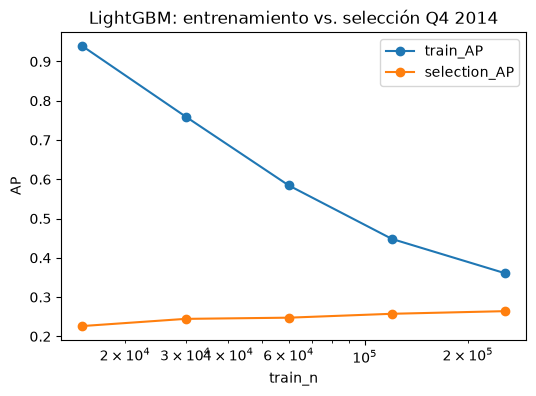

In [6]:
lc = pd.read_csv(OUT/'learning_curve.csv'); display(lc.round(4))
ax = lc.plot(x='train_n', y=['train_AP','selection_AP'], marker='o', logx=True, figsize=(6,4))
ax.set_ylabel('AP'); ax.set_title('LightGBM: entrenamiento vs. selección Q4 2014'); plt.show()

La brecha entrenamiento-selección indica varianza, y la curva de selección crece con rendimientos decrecientes.